# MILES-GUESS Classification Example Notebook (PyTorch)

John Schreck, David John Gagne, Charlie Becker, Gabrielle Gantos, Dhamma Kimpara, Thomas Martin

This retains the authors' precipitation-type task, four-class output order, 84 input fields, four 212-unit hidden layers, dropout 0.1167, batch size 1024, Adam learning rate 0.001, and **100 epochs with at most 10 batches per epoch** for each classifier. It retains the original quality filters, held-out case-study dates/date cutoff, and day-grouped training/validation split. No generated data or replacement architecture is used.

The configuration's original mPING parquet path is the default. Set `MILES_PTYPE_DATA` below (or as an environment variable) to the **local copy of that data**, or explicitly select the authors' bundled `data/ptype_sample.parquet` sample. A sample run is a demonstration on those original sample observations, not a reproduction of the full-data paper results. The data loader requires `pyarrow` (`python -m pip install -e ".[torch,data,notebooks]"`).

Two genuine call-site corrections are required: `CrossEntropyLoss` receives **logits**, so the standard classifier's output softmax is disabled during training and applied once during evaluation. The evidential loss and architecture remain unchanged; its device is passed by keyword so it cannot be mistaken for class weights (an original positional-call error). CPU is the default; initialization and shuffling use the existing configuration seed. Metrics are aggregated by observations, and the two models' results are kept separate. The original notebook's per-feature robust scaling (`groups=[]`) is retained and fitted only on training data.


#### Objective

This notebook is meant to demonstrate a functional example of how to use the miles-guess repository for training an evidential classification model.

Steps to get this notebook running:
1) Follow package installation steps in the miles-guess [ReadMe](https://github.com/ai2es/miles-guess/tree/main).
2) Run the cells in this notebook in order.

In [1]:
from pathlib import Path
from collections import defaultdict
import os
import copy
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from mlguess.keras.data import load_ptype_uq, preprocess_data
from mlguess.torch.models import CategoricalDNN, seed_everything
from mlguess.torch.class_losses import edl_digamma_loss
from mlguess.evaluation import evaluate_classifier
REPO_ROOT = next((path for path in (Path.cwd(), Path.cwd().parent)
                  if (path / "config").is_dir() and (path / "mlguess").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Run this notebook from the repository root or its notebooks directory.")


### Load a config file

In [2]:
config = REPO_ROOT / "config/evidential_classifier_torch.yml"
# Optional explicit local path; None preserves the authors' full-data YAML path.
MILES_PTYPE_DATA = os.environ.get("MILES_PTYPE_DATA")
# To demonstrate on the authors' bundled sample instead, explicitly uncomment:
# MILES_PTYPE_DATA = REPO_ROOT / "data/ptype_sample.parquet"


In [3]:
with config.open() as cf:
    conf = yaml.safe_load(cf)
seed_everything(conf["seed"])
if MILES_PTYPE_DATA is not None:
    conf["data_path"] = str(Path(MILES_PTYPE_DATA).expanduser().resolve())
if not Path(conf["data_path"]).is_file():
    raise FileNotFoundError(
        f"Authors' mPING parquet not found: {conf['data_path']}\n"
        "Set MILES_PTYPE_DATA to your local original dataset, or explicitly select "
        "REPO_ROOT / 'data/ptype_sample.parquet' in the preceding cell. No generated fallback is used.")
print(f"Precipitation dataset: {conf['data_path']}")
device = torch.device("cpu")


Precipitation dataset: /workspace/scratch/d7d34632ac75/miles-guess/data/ptype_sample.parquet


### Load the training splits

In [4]:
input_features = []
for features in ["TEMP_C", "T_DEWPOINT_C", "UGRD_m/s", "VGRD_m/s"]:
    input_features += conf["data"][features]
output_features = conf["data"]["ptypes"]
_conf = copy.deepcopy(conf)
_conf.update(conf["data"])
data = load_ptype_uq(_conf, data_split=0, verbose=1, drop_mixed=False)
# The original notebook computes groups but explicitly passes groups=[]; preserve that preprocessing.
scaled_data, scalers = preprocess_data(
    data, input_features, output_features,
    scaler_type=conf["data"]["scaler_type"], encoder_type="onehot", groups=[])
for first, second in (("train", "val"), ("train", "test"), ("val", "test")):
    assert set(data[first]["day"]).isdisjoint(data[second]["day"])
if data["test"].empty:
    raise ValueError("The selected original dataset contains no held-out test observations for the configured dates.")
display(pd.DataFrame({split: {"observations": len(frame), "days": frame["day"].nunique()}
                      for split, frame in data.items()}).T)
print("Class probability columns:", output_features)


Class probability columns: ['ra_percent', 'sn_percent', 'pl_percent', 'fzra_percent']


,observations,days
train,7225,1500
val,908,167
test,4031,600


In [5]:
def one_hot_embedding(labels, num_classes=4):
    return torch.nn.functional.one_hot(labels, num_classes=num_classes).to(torch.float32)


### Convert the pandas dataframe into torch tensors, wrap in Dataset then Dataloader

In [6]:
X_train = torch.FloatTensor(scaled_data["train_x"].values)
y_train = torch.LongTensor(np.argmax(scaled_data["train_y"], axis=1))

batch_size = 1024

# Create dataset and dataloader
dataset = TensorDataset(X_train, y_train)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

### First lets train a standard (non-evidential) classifier

In [7]:
# CrossEntropyLoss applies log-softmax internally: supply logits, not a second softmax.
conf["model"]["softmax"] = False


In [8]:
mlp = CategoricalDNN(**conf["model"]).to(device)


In [9]:
mlp

Out[9]: 
CategoricalDNN(
  (fcn): Sequential(
    (0): Linear(in_features=84, out_features=212, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Dropout(p=0.1167, inplace=False)
    (3): Linear(in_features=212, out_features=212, bias=True)
    (4): LeakyReLU(negative_slope=0.01)
    (5): Dropout(p=0.1167, inplace=False)
    (6): Linear(in_features=212, out_features=212, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Dropout(p=0.1167, inplace=False)
    (9): Linear(in_features=212, out_features=212, bias=True)
    (10): LeakyReLU(negative_slope=0.01)
    (11): Dropout(p=0.1167, inplace=False)
    (12): Linear(in_features=212, out_features=4, bias=True)
  )
)


### Train the model

In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp.parameters(), lr=0.001)
num_epochs = 100
batches_per_epoch = 10
point_history = []
for epoch in range(num_epochs):
    mlp.train()
    loss_sum, correct, count = 0.0, 0, 0
    for k, (batch_X, batch_y) in enumerate(dataloader):
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        outputs = mlp(batch_X)
        loss = criterion(outputs, batch_y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(batch_y)
        correct += int((outputs.argmax(dim=1) == batch_y).sum())
        count += len(batch_y)
        if (k + 1) == batches_per_epoch:
            break
    point_history.append({"epoch": epoch + 1, "loss": loss_sum / count, "accuracy": correct / count})
point_history = pd.DataFrame(point_history)


In [11]:
display(point_history.tail())


,epoch,loss,accuracy
95,96,0.281424,0.898131
96,97,0.279655,0.899239
97,98,0.281498,0.899516
98,99,0.281116,0.897855
99,100,0.286497,0.894948


### Next lets train an evidential classifier

In [12]:
conf["model"]["softmax"] = False
conf["model"]["lng"] = False

In [13]:
ev_mlp = CategoricalDNN(**conf["model"]).to(device)


In [14]:
ev_mlp

Out[14]: 
CategoricalDNN(
  (fcn): Sequential(
    (0): Linear(in_features=84, out_features=212, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Dropout(p=0.1167, inplace=False)
    (3): Linear(in_features=212, out_features=212, bias=True)
    (4): LeakyReLU(negative_slope=0.01)
    (5): Dropout(p=0.1167, inplace=False)
    (6): Linear(in_features=212, out_features=212, bias=True)
    (7): LeakyReLU(negative_slope=0.01)
    (8): Dropout(p=0.1167, inplace=False)
    (9): Linear(in_features=212, out_features=212, bias=True)
    (10): LeakyReLU(negative_slope=0.01)
    (11): Dropout(p=0.1167, inplace=False)
    (12): Linear(in_features=212, out_features=4, bias=True)
  )
)


### Evidential classifier training

The original digamma evidential loss, ReLU evidence transformation, 10-epoch KL annealing, and training cap are retained. The four class columns are the YAML's rain, snow, ice-pellet, and freezing-rain order. No test data are used in fitting or checkpoint selection; both examples evaluate their final original-length training run.


**Notation aligned with the paper (Eqs. 3–7).** The index $n$ denotes an input/observation and $k\in\{1,\ldots,K\}$ denotes a class ($K=4$ here). The class indicator $y_{n,k}$ is 1 when the observed class is $k$ and 0 otherwise. The network produces nonnegative evidence $e_{n,k}$, giving
\[
\alpha_{n,k}=e_{n,k}+1,\qquad
S_n=\sum_{k=1}^{K}\alpha_{n,k},\qquad
\boldsymbol p_n\sim\operatorname{Dir}(\boldsymbol\alpha_n).
\]
Here $\boldsymbol p_n$ is the **latent probability vector**. The predicted probability is its mean (Eq. 4):
\[
\widehat p_{n,k}=\mathbb E[p_{n,k}]
=\frac{\alpha_{n,k}}{S_n}.
\]
We write $S_n$ to make explicit the observation dependence of the paper's $S$. Classification $\alpha_{n,k}$ is a Dirichlet parameter; it is distinct from the NIG shape parameter $\alpha_n$ used in the regression notebooks. Belief mass and DST uncertainty mass (Eqs. 5–7), written with an observation index, are
\[
b_{n,k}=\frac{e_{n,k}}{S_n},\qquad
u_n=\frac{K}{S_n},\qquad
u_n+\sum_k b_{n,k}=1.
\]

In the code, `alpha` denotes $\alpha_{n,k}$ and `evidential_probabilities` contains $\widehat p_{n,k}$, not draws of the latent $p_{n,k}$. The arrays `aleatoric`, `epistemic`, and `vacuity` contain the variance components and $u_n$, respectively.


In [15]:
criterion = edl_digamma_loss
optimizer = optim.Adam(ev_mlp.parameters(), lr=0.001)
num_epochs = 100
batches_per_epoch = 10
num_classes = 4
assert num_classes == len(output_features)
evidential_history = []
for epoch in range(num_epochs):
    ev_mlp.train()
    loss_sum, correct, count = 0.0, 0, 0
    for k, (batch_X, batch_y) in enumerate(dataloader):
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        outputs = ev_mlp(batch_X)
        batch_y_onehot = one_hot_embedding(batch_y, num_classes)
        loss = criterion(outputs, batch_y_onehot, epoch, num_classes, 10, device=batch_y.device)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(batch_y)
        # Evidence is ReLU(output), so its normalized Dirichlet mean defines predictions.
        alpha = torch.relu(outputs.detach()) + 1
        correct += int((alpha.argmax(dim=1) == batch_y).sum())
        count += len(batch_y)
        if (k + 1) == batches_per_epoch:
            break
    evidential_history.append({"epoch": epoch + 1, "loss": loss_sum / count, "accuracy": correct / count})
evidential_history = pd.DataFrame(evidential_history)


In [16]:
display(evidential_history.tail())


,epoch,loss,accuracy
95,96,0.630306,0.885398
96,97,0.635771,0.884983
97,98,0.629338,0.884983
98,99,0.624482,0.885260
99,100,0.625697,0.888166


## Held-out test evaluation

Both classifiers now predict every test observation in batches with dropout disabled. Standard logits are converted to probabilities with one softmax; evidential predictions use the normalized Dirichlet mean, not softmax(logits). We report accuracy, log loss, multiclass Brier score (sum over classes, then mean over observations), and top-label expected calibration error (10 equal-width bins). Reliability diagrams include each occupied bin's sample count.

Our multiclass Brier score uses $\widehat p_{n,k}$ and sums over classes before averaging over observations; it is $K$ times the paper's class-averaged definition in Eq. (27).


For each class, the paper's law-of-total-variance decomposition (Eqs. 20–23) is
\[
\underbrace{\mathbb E[\operatorname{Var}(y_{n,k}\mid p_{n,k})]}_{\text{aleatoric}}
=\mathbb E[p_{n,k}(1-p_{n,k})]
=\widehat p_{n,k}(1-\widehat p_{n,k})\frac{S_n}{S_n+1},
\]
\[
\underbrace{\operatorname{Var}(\mathbb E[y_{n,k}\mid p_{n,k}])}_{\text{epistemic}}
=\operatorname{Var}(p_{n,k})
=\frac{\widehat p_{n,k}(1-\widehat p_{n,k})}{S_n+1}.
\]
Their sum is the total class-indicator variance
\[
\operatorname{Var}(y_{n,k})
=\widehat p_{n,k}(1-\widehat p_{n,k}).
\]
The variance traces plotted below sum the corresponding per-class variances over $k$ for each observation $n$; they are not variances across observations. The separate statistic `K / sum(alpha)` is the paper's DST uncertainty mass $u_n=K/S_n$ (Eq. 6), also called **evidential vacuity**. It is not an additive variance component.


In [17]:
def batched_classifier_predictions(trained_model, features, *, evidential, batch_size=1024):
    trained_model.eval()
    collected = []
    with torch.inference_mode():
        for start in range(0, len(features), batch_size):
            inputs = torch.as_tensor(features[start:start + batch_size], dtype=torch.float32, device=device)
            logits = trained_model(inputs)
            if evidential:
                collected.append(tuple(value.cpu().numpy() for value in trained_model.calc_uncertainty(logits)))
            else:
                collected.append(torch.softmax(logits, dim=1).cpu().numpy())
    if evidential:
        return tuple(np.concatenate([chunk[index] for chunk in collected]) for index in range(4))
    return np.concatenate(collected)

test_features = scaled_data["test_x"].to_numpy()
test_labels = np.argmax(scaled_data["test_y"], axis=1).astype(np.int64)
point_probabilities = batched_classifier_predictions(mlp, test_features, evidential=False)
evidential_probabilities, vacuity, aleatoric, epistemic = batched_classifier_predictions(
    ev_mlp, test_features, evidential=True)
point_test = evaluate_classifier(test_labels, point_probabilities, n_bins=10)
evidential_test = evaluate_classifier(test_labels, evidential_probabilities, n_bins=10)
test_metrics = pd.DataFrame([point_test["metrics"], evidential_test["metrics"]],
                            index=["Standard classifier", "Evidential classifier"])
display(test_metrics)
display(pd.DataFrame({"class": output_features, "test_count": np.bincount(test_labels, minlength=num_classes)}))
assert np.allclose(aleatoric + epistemic, evidential_probabilities * (1 - evidential_probabilities),
                   rtol=1e-5, atol=1e-7)


,accuracy,log_loss,brier,ece
Standard classifier,0.879682,0.330680,0.169357,0.026358
Evidential classifier,0.860084,0.552612,0.255914,0.195986


,class,test_count
0,ra_percent,2333
1,sn_percent,1321
2,pl_percent,238
3,fzra_percent,139


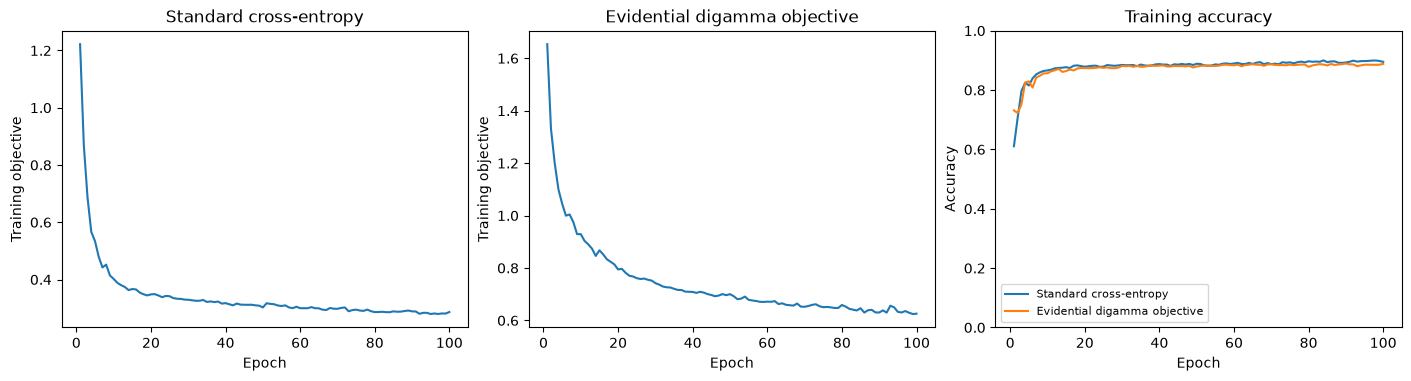

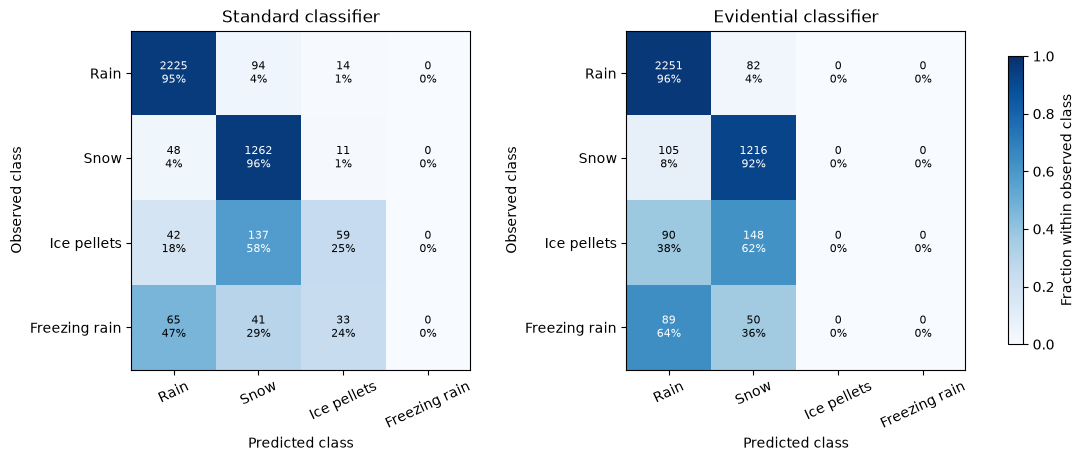

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7), constrained_layout=True)
for index, (history, title) in enumerate(((point_history, "Standard cross-entropy"),
                                         (evidential_history, "Evidential digamma objective"))):
    axes[index].plot(history["epoch"], history["loss"])
    axes[index].set(title=title, xlabel="Epoch", ylabel="Training objective")
    axes[2].plot(history["epoch"], history["accuracy"], label=title)
axes[2].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1))
axes[2].legend(fontsize=8)
plt.show()

class_names = ["Rain", "Snow", "Ice pellets", "Freezing rain"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, result, title in zip(axes, [point_test, evidential_test], test_metrics.index):
    counts = result["confusion"]
    row_totals = counts.sum(axis=1, keepdims=True)
    normalized = np.divide(counts, row_totals, out=np.zeros_like(counts, dtype=float), where=row_totals != 0)
    im = ax.imshow(normalized, vmin=0, vmax=1, cmap="Blues")
    for i in range(num_classes):
        for j in range(num_classes):
            ax.text(j, i, f"{counts[i, j]}\n{normalized[i, j]:.0%}", ha="center", va="center",
                    color="white" if normalized[i, j] > 0.5 else "black", fontsize=8)
    ax.set(xticks=np.arange(num_classes), yticks=np.arange(num_classes),
           xticklabels=class_names, yticklabels=class_names, xlabel="Predicted class", ylabel="Observed class", title=title)
    ax.tick_params(axis="x", rotation=25)
fig.colorbar(im, ax=axes, label="Fraction within observed class", shrink=0.85)
plt.show()


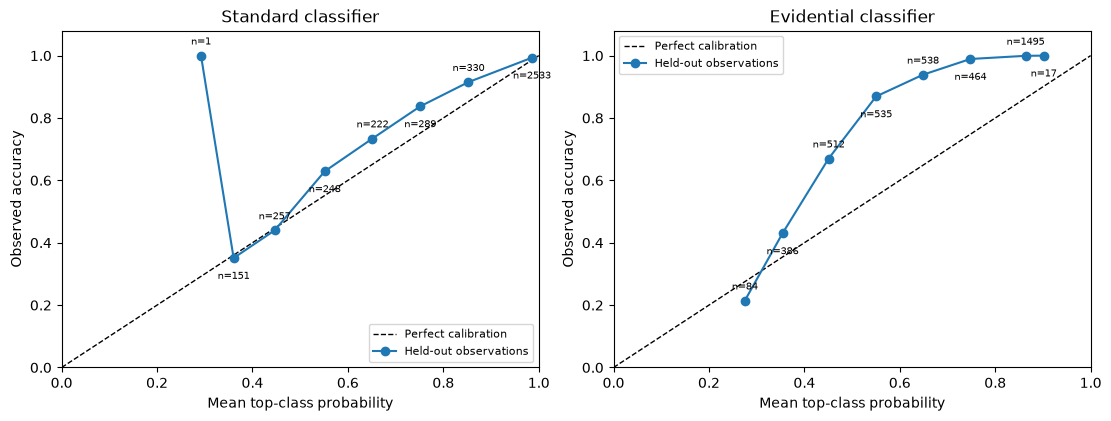

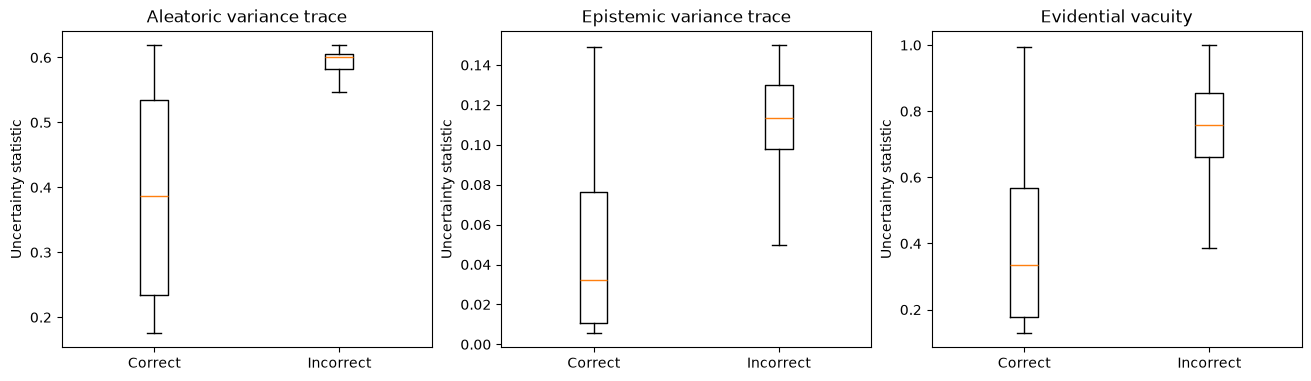

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), constrained_layout=True)
for ax, result, title in zip(axes, [point_test, evidential_test], test_metrics.index):
    reliability = result["reliability"].query("count > 0")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
    ax.plot(reliability["confidence"], reliability["accuracy"], "o-", label="Held-out observations")
    for index, row in enumerate(reliability.itertuples()):
        ax.annotate(f"n={row.count}", (row.confidence, row.accuracy), xytext=(0, 8 if index % 2 == 0 else -15),
                    textcoords="offset points", fontsize=7, ha="center")
    ax.set(title=title, xlabel="Mean top-class probability", ylabel="Observed accuracy",
           xlim=(0, 1), ylim=(0, 1.08))
    ax.legend(fontsize=8)
plt.show()

correct = evidential_probabilities.argmax(axis=1) == test_labels
traces = {"Aleatoric variance trace": aleatoric.sum(axis=1),
          "Epistemic variance trace": epistemic.sum(axis=1), "Evidential vacuity": vacuity.ravel()}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), constrained_layout=True)
for ax, (title, values) in zip(axes, traces.items()):
    nonempty = [(label, values[mask]) for label, mask in (("Correct", correct), ("Incorrect", ~correct)) if mask.any()]
    ax.boxplot([values for _, values in nonempty], tick_labels=[label for label, _ in nonempty], showfliers=False)
    ax.set(title=title, ylabel="Uncertainty statistic")
plt.show()


In [20]:
OUTPUT_DIR = REPO_ROOT / "outputs/authors_classifier_torch"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv")
for name, result in (("standard", point_test), ("evidential", evidential_test)):
    result["reliability"].to_csv(OUTPUT_DIR / f"{name}_reliability.csv", index=False)
    pd.DataFrame(result["confusion"], index=output_features, columns=output_features).to_csv(
        OUTPUT_DIR / f"{name}_confusion.csv")
predictions = pd.DataFrame({"source_row": data["test"].index, "day": data["test"]["day"].to_numpy(),
                            "observed_class": test_labels, "evidential_vacuity": vacuity.ravel()})
for index, name in enumerate(output_features):
    predictions[f"standard_probability_{name}"] = point_probabilities[:, index]
    predictions[f"evidential_probability_{name}"] = evidential_probabilities[:, index]
    predictions[f"aleatoric_variance_{name}"] = aleatoric[:, index]
    predictions[f"epistemic_variance_{name}"] = epistemic[:, index]
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print(f"Saved full held-out predictions and metrics to {OUTPUT_DIR}")


Saved full held-out predictions and metrics to /workspace/scratch/d7d34632ac75/miles-guess/outputs/authors_classifier_torch


### Results and interpretation

The tables and figures above describe the authors' configured models on the specified held-out observations. A single train/test run does not establish calibration on every future dataset. Use the existing validation partition for subsequent model development and a fresh test set for final evaluation.

Inspect the individual confusion-matrix rows as well as overall accuracy: common rain and snow observations can conceal weak performance on ice pellets or freezing rain. Reliability-bin counts indicate where calibration estimates have very little support. The uncertainty boxplots describe this test set; vacuity is not a guarantee that every incorrect or unfamiliar observation will be detected.


### Questions? Email John Schreck (schreck@ucar.edu)